# MECHA, 7: a tomato root by day and by night

**What you will learn:** give the cells and the soil their osmotic potentials, compare a root's water uptake by night
and by day, in a well-watered and in a stressful soil, and find when a stressed root stops taking up water.

**You need:** tutorials 1 and 2. **Run time:** about 15 seconds.

This tutorial follows an example of MECHA's developers (`example/legacy/root_example.py`, a tomato root's water
pump).

## 1. Osmotic potentials, in a few words

Water moves from a high to a low **water potential**. Two parts of it matter here:

- the **pressure** potential: the push or the pull on the water (the xylem pulls when the leaves transpire);
- the **osmotic** potential: the dissolved substances (sugars, salts) lower it. The more concentrated, the more
  negative.

A cell's membrane lets water through but holds most solutes back. A cell with a more negative osmotic potential than
its surroundings therefore draws water in. MECHA gives each tissue its own osmotic potential, and the soil solution
its own (a salty or drying soil has a more negative one). All values are in hPa (1 MPa = 10 000 hPa).

## 2. The tomato root

`TOMATO_ROOT` gives GRANAP's dicot root a tomato's young root: a xylem star with two arms, its phloem and cambium,
its cell sizes.

*Two differences with the developers' example:* their cortex has an inner, a middle and an outer layer, and they
remove the exodermis. GRANAP's anatomy parameters change the existing layers but cannot add or remove one, so here
the cortex is four similar layers and the exodermis stays.

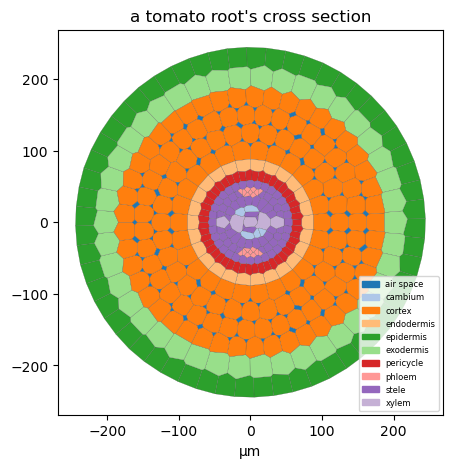

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.mecha.simulation import TOMATO_ROOT, simulate

section = simulate(anatomy=TOMATO_ROOT)
section.draw("tissues")
plt.title("a tomato root's cross section");

## 3. Four situations

The example's four situations differ by the osmotic potentials of the tissues and of the soil, and by the xylem's
pressure:

- **night**: the leaves hardly transpire, so the xylem pulls gently (−2500 hPa);
- **day**: transpiration pulls harder (−4700 hPa) and the cells hold more sugars;
- **stress**: the soil solution is concentrated (−7500 hPa instead of −1500), as in a salty or drying soil. The
  stressed root has a **suberized endodermis** (barrier 3), a waxy layer that slows the water down, while the
  well-watered root has only a Casparian strip (barrier 1).

*(The example uses MECHA's barrier codes 9 and 6. Its root has no exodermis, so both amount to a Casparian strip
there; here, with GRANAP's exodermis kept, a Casparian strip (1) and a suberized endodermis (3) give the contrast its
"with suberin" case intends.)*

In [2]:
def scenario(**changes):
    """The example's base osmotic potentials (hPa) with *changes*; the exodermis and the endodermis halfway between
    their neighbours, as the example sets them."""
    values = dict(os_hetero=4, osmotic_left_soil=-1.5E3, osmotic_right_soil=-1.5E3, osmotic_epi=-6.8E3,
                  os_cortex=-8.3E3, osmotic_peri=-5.5E3, osmotic_stele=-5.5E3, osmotic_xyl=-1.4E3,
                  osmotic_sieve=-1.0E4)
    values.update(changes)
    values["osmotic_exo"] = (values["osmotic_epi"] + values["os_cortex"]) / 2
    values["osmotic_endo"] = (values["osmotic_peri"] + values["os_cortex"]) / 2
    return values


stress_night = dict(osmotic_left_soil=-7.5E3, osmotic_right_soil=-7.5E3, osmotic_epi=-8.0E3, os_cortex=-7.6E3,
                    osmotic_peri=-4E3, osmotic_stele=-4E3, osmotic_xyl=-3.7E3)
SITUATIONS = {   # name: (osmotic potentials, xylem pressure (hPa), barrier)
    "control, night": (scenario(osmotic_peri=-5E3, osmotic_stele=-5E3), -2.5E3, 1),
    "control, day": (scenario(osmotic_epi=-7.5E3, os_cortex=-6.8E3, osmotic_peri=-6E3, osmotic_stele=-6E3), -4.7E3, 1),
    "stress, night": (scenario(**stress_night), -2.5E3, 3),
    "stress, day": (scenario(**dict(stress_night, osmotic_epi=-8.5E3, os_cortex=-7.5E3, osmotic_peri=-5E3,
                                    osmotic_stele=-5E3, osmotic_xyl=-3.6E3)), -8.0E3, 3),
}
results = {name: simulate(anatomy=TOMATO_ROOT, osmotic=osmotic, xylem_psi=pressure, barrier=barrier)
           for name, (osmotic, pressure, barrier) in SITUATIONS.items()}
pd.DataFrame({name: {"water uptake (cm³ d⁻¹)": result.summary["uptake"]} for name, result in results.items()}).T

,water uptake (cm³ d⁻¹)
"control, night",0.001055
"control, day",0.001517
"stress, night",0.000245
"stress, day",0.000707


**Reading the table.** By day the root takes up more water than by night (the xylem pulls harder). In the stressful
soil, less: the soil solution's low osmotic potential holds the water back, and the suberized endodermis slows it.

## 4. The cells' pressure

With osmotic potentials, the potential MECHA computes for each cell and wall is its **pressure** potential: in a
cell, its turgor, the pressure that keeps it firm. Here against the distance to the centre, from the soil (outside,
right) to the xylem (centre, left).

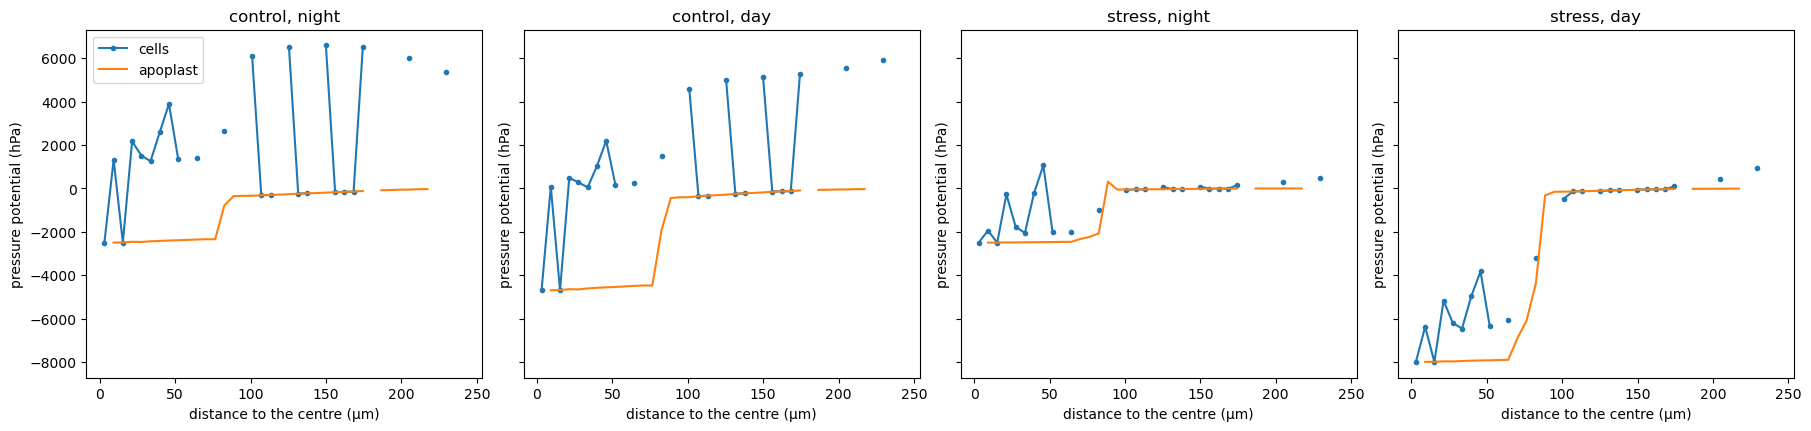

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharey=True, layout="constrained")
from openalea.mecha import plots
for ax, (name, result) in zip(axes, results.items()):
    plots.radial_profile(ax, result.frame())
    ax.set(title=name, ylabel="pressure potential (hPa)")
axes[0].legend()
plt.show()

In the well-watered root, the cortex cells hold sugars (an osmotic potential near −8000 hPa): they take up water
until their turgor reaches about +6000 hPa, while the walls stay near the soil's pressure (0) outside the endodermis
and near the xylem's inside. In the stressful soil, the cortex cells' turgor stays near 0: the soil solution is
nearly as concentrated as they are. By day, the xylem's pull lowers the pressure inside the endodermis.

## 5. When does a stressed root take up water?

The example's question: under stress, does the root take up water at all, and how does that depend on the osmotic
potential of the pericycle and the stele (the cells around the xylem)? Both are set equal and lowered from −1000 to
−8000 hPa, by night and by day.

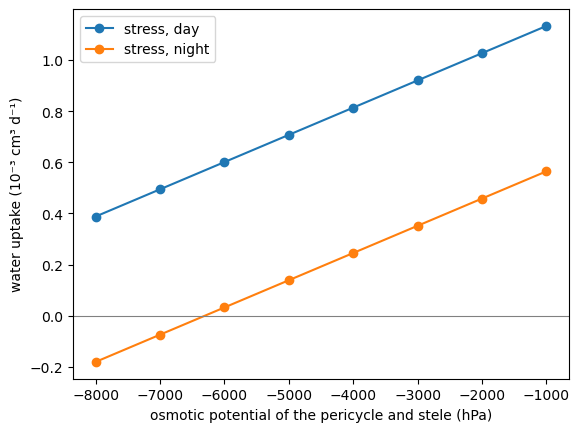

In [4]:
values = np.linspace(-1E3, -8E3, 8)
rows = []
for name in ("stress, night", "stress, day"):
    osmotic, pressure, barrier = SITUATIONS[name]
    for value in values:
        changed = scenario(**{**{k: v for k, v in osmotic.items() if k not in ("osmotic_exo", "osmotic_endo")},
                              "osmotic_peri": value, "osmotic_stele": value})
        result = simulate(anatomy=TOMATO_ROOT, osmotic=changed, xylem_psi=pressure, barrier=barrier)
        rows.append(dict(situation=name, stele=value, uptake=result.summary["uptake"]))
sweep = pd.DataFrame(rows)
for name, part in sweep.groupby("situation"):
    plt.plot(part["stele"], part["uptake"] * 1e3, "o-", label=name)
plt.axhline(0., color="0.5", lw=0.8)
plt.xlabel("osmotic potential of the pericycle and stele (hPa)"); plt.ylabel("water uptake (10⁻³ cm³ d⁻¹)")
plt.legend();

**Reading the curves.** Lowering the stele's osmotic potential *reduces* the uptake. Concentrated stele cells draw
water from the xylem around them, which then carries less to the shoot. By night, with the xylem pulling gently,
the uptake falls below zero between −6000 and −7000 hPa: the root then loses water to the stressful soil. By day,
the xylem's stronger pull keeps the uptake positive over the whole range.

## Try it yourself

1. Make the stressed root's endodermis unsuberized (barrier 1). Does the night uptake stay positive?
2. Make the soil solution even more concentrated (−9000 hPa). At which stele potential does the night uptake
   reverse?
3. Compare `section.draw("potential")` for the control and the stress, by day.